# 03 · Clustering households into privacy profiles

Groups the 5,000 synthetic households (notebook 02, v3) into **profiles**: sets of households with similar decisions. Each
profile becomes a candidate **household preset** in notebook 04; notebook 05 learns which onboarding answers place a
household in its profile.

**Method: Smullen, Feng, Zhang, Sadeh 2020 (S20), adapted.**

| S20 | Here |
| --- | --- |
| Agglomerative hierarchical clustering of people | **k-means** on each household's 224 cell averages; Ward and average linkage for comparison. Ward's profiles are not stable when the households are resampled (below), k-means' are |
| Features: preferences averaged by app category × permission × purpose | Each household's average acceptance per **cell** (data type × purpose × handling context; notebook 02) |
| A profile recommends a setting only where ≥ 80% of its members agree (70/80/90% tested) | Same, per item; the share of items a profile decides this way is its **coverage** |
| No consensus → ask the user | **Never ask** (CableLabs guidance): the profile still has to decide. Three fallbacks are compared below |
| k from 2 to 40, 10-fold cross-validation | k from 1 to 40, 5-fold cross-validation (5 folds keep the run to about a minute) |
| Profiling with decision trees | Here a test household is placed in its *nearest* profile using its own decisions, which is an upper bound. The realistic placement from a few answers is notebook 05 |

**Accuracy** = how often the profile's decision equals the household's own decision on an item (deny / allow / allow
with a specific condition must match exactly). **Allow/deny accuracy** counts every *allow if* as allow; it is the
measure S20 reports (75–90% across k), so it is the one compared with the study below.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import KFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, REF = ROOT / "data", ROOT / "references"
DECISIONS = json.loads((ROOT / "decisions.json").read_text())   # team decisions, shared by notebooks 03-05
TEAM_K = DECISIONS["presets_k"]
items = pd.read_csv(DATA / "items.csv")
cells = pd.read_csv(DATA / "cells.csv")
H = pd.read_csv(DATA / "households.csv")
D = np.load(DATA / "decisions.npy")              # households x items, codes 0..4
C = np.load(DATA / "decisions_cells.npy")        # households x cells, average acceptance 0..1
CODES = {0: "deny", 1: "allow", 2: "allow if not kept", 3: "allow if in-home only", 4: "allow if on-device only"}
n, m = D.shape
real = items.in_corpus.to_numpy()
plausible = items.plausible.to_numpy()
home = ~items.leaves_home.to_numpy()
short = lambda term: term.split(":", 1)[1]
print(f"{n:,} households, {m:,} items, {C.shape[1]} cells, {real.sum()} real-device items")

5,000 households, 6,272 items, 224 cells, 52 real-device items


## Settings

In [2]:
KS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32, 40]   # numbers of profiles to try
THRESHOLD = 0.8                                     # S20: 80% agreement was the best trade-off
THRESHOLDS = [0.7, 0.8, 0.9]                        # also tested, as in S20
METHODS = ["ward", "kmeans", "average_manhattan"]
PROFILE_METHOD = "kmeans"                           # the method the presets are built from (see "Are the profiles well defined?")
KMEANS_INIT = 10                                    # k-means restarts for the final profiles
FOLDS = 5
SEED = 0

## How a profile is built and used

1. **Cluster** the training households on their cell averages into *k* groups.
2. **Profile** = for every item, the most common decision in the group (*majority*) and the share of the group that
   made it (*agreement*).
3. A test household is assigned the profile whose cell averages are closest (Manhattan distance).
4. For each item: if agreement ≥ threshold, the profile **decides** (covered); otherwise a **fallback** decides:
   - **majority**: use the group's most common decision anyway;
   - **home/away**: allow if the flow stays home, deny if it leaves (cautious; like CableLabs' bulb firmware);
   - **strict**: deny.

In [3]:
def cluster(method, X, ks, n_init=3):
    # Labels 0..k-1 for each k. Hierarchical methods build one tree and cut it at each k.
    if method == "ward":
        Z = linkage(X, "ward")
    elif method == "average_manhattan":
        Z = linkage(pdist(X, "cityblock"), "average")
    out = {}
    for k in ks:
        if k == 1:
            out[k] = np.zeros(len(X), dtype=int)
        elif method == "kmeans":
            out[k] = KMeans(k, n_init=n_init, random_state=SEED).fit_predict(X)
        else:
            out[k] = fcluster(Z, k, "maxclust") - 1
    return out

def build_profiles(Dg, labels, k):
    # Majority decision and agreement per profile and item (matrix products count each decision code per group).
    member = np.zeros((k, len(labels)), dtype=np.float32)
    member[labels, np.arange(len(labels))] = 1
    size = member.sum(axis=1, keepdims=True)
    counts = np.stack([member @ (Dg == c).astype(np.float32) for c in range(5)])   # 5 x k x items
    return counts.argmax(axis=0).astype(np.uint8), counts.max(axis=0) / np.maximum(size, 1)

def centroids(Xg, labels, k):
    return np.stack([Xg[labels == c].mean(axis=0) for c in range(k)])

def assign(Xt, cent):
    return np.abs(Xt[:, None, :] - cent[None]).sum(axis=2).argmin(axis=1)

## Cross-validation over methods and k

In [4]:
rows = []
started = time.time()
folds = list(KFold(FOLDS, shuffle=True, random_state=SEED).split(D))
for method in METHODS:
    for fold, (tr, te) in enumerate(folds):
        labels = cluster(method, C[tr], KS)
        for k in KS:
            lab = labels[k]
            majority, agreement = build_profiles(D[tr], lab, k)
            a = assign(C[te], centroids(C[tr], lab, k))
            pm, pa, Dt = majority[a], agreement[a], D[te]
            hit = pm == Dt
            row = dict(method=method, fold=fold, k=k, largest_profile=np.bincount(lab, minlength=k).max() / len(lab))
            for th in THRESHOLDS:
                covered = pa >= th
                tag = f"{int(th * 100)}"
                row[f"coverage_{tag}"] = covered.mean()
                row[f"acc_covered_{tag}"] = hit[covered].mean()
                row[f"acc_home_away_{tag}"] = np.where(covered, hit, np.where(home[None], 1, 0) == Dt).mean()
                row[f"acc_strict_{tag}"] = np.where(covered, hit, Dt == 0).mean()
                row[f"real_coverage_{tag}"] = covered[:, real].mean()
            row["acc_majority"] = hit.mean()
            row["acc_allow_deny"] = ((pm != 0) == (Dt != 0)).mean()
            row["acc_majority_plausible"] = hit[:, plausible].mean()
            row["acc_majority_real"] = hit[:, real].mean()
            rows.append(row)
    print(f"{method}: done ({time.time() - started:.0f} s)")
cv = pd.DataFrame(rows).groupby(["method", "k"]).mean(numeric_only=True).drop(columns="fold")

ward: done (17 s)


kmeans: done (34 s)


average_manhattan: done (52 s)


## Results

### Accuracy and coverage by number of profiles

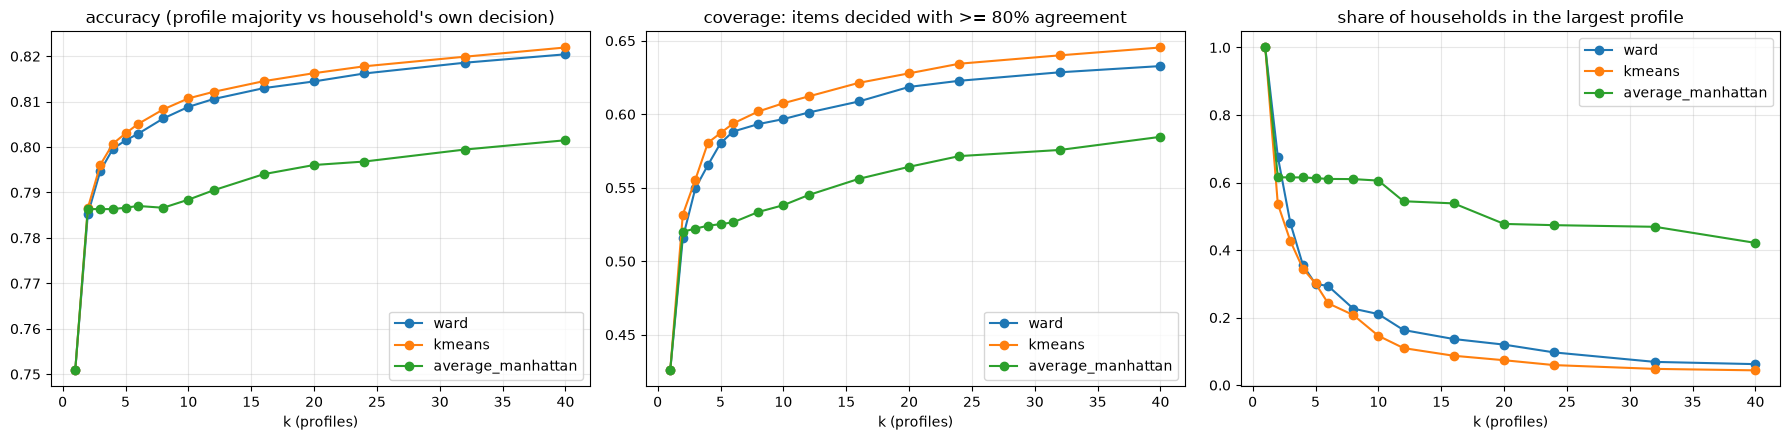

,acc_majority,acc_allow_deny,acc_majority_plausible,acc_majority_real,coverage_80,acc_covered_80,largest_profile
k,,,,,,,
1,0.751,0.772,0.757,0.883,0.426,0.914,1.000
2,0.787,0.811,0.792,0.889,0.532,0.931,0.537
3,0.796,0.819,0.802,0.891,0.556,0.934,0.427
4,0.801,0.824,0.806,0.893,0.581,0.932,0.345
5,0.803,0.827,0.808,0.895,0.587,0.933,0.301
6,0.805,0.829,0.810,0.896,0.594,0.932,0.242
8,0.808,0.832,0.814,0.897,0.602,0.933,0.208
10,0.811,0.835,0.816,0.897,0.608,0.934,0.146
12,0.812,0.836,0.817,0.898,0.612,0.934,0.110


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for method in METHODS:
    r = cv.loc[method]
    axes[0].plot(r.index, r.acc_majority, marker="o", label=method)
    axes[1].plot(r.index, r.coverage_80, marker="o", label=method)
    axes[2].plot(r.index, r.largest_profile, marker="o", label=method)
axes[0].set_title("accuracy (profile majority vs household's own decision)")
axes[1].set_title("coverage: items decided with >= 80% agreement")
axes[2].set_title("share of households in the largest profile")
for ax in axes: ax.set_xlabel("k (profiles)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
cv.loc[PROFILE_METHOD, ["acc_majority", "acc_allow_deny", "acc_majority_plausible", "acc_majority_real", "coverage_80", "acc_covered_80", "largest_profile"]].round(3)

### How many profiles do the decisions need?

What each step up in k buys, before any question is asked (each test household gets its nearest profile, the upper
bound). Gains shrink quickly; notebook 05 makes the actual choice, because more profiles also need more questions.

In [6]:
w = cv.loc[PROFILE_METHOD]
steps = pd.DataFrame({"accuracy": w.acc_majority, "allow/deny": w.acc_allow_deny, "coverage 80%": w.coverage_80})
steps["gain over k = 1 (points)"] = (steps.accuracy - steps.accuracy.loc[1]) * 100
steps["share of the k = 40 gain"] = (steps.accuracy - steps.accuracy.loc[1]) / (steps.accuracy.loc[40] - steps.accuracy.loc[1])
steps["gain per added profile (points)"] = steps.accuracy.diff() * 100 / pd.Series(steps.index, index=steps.index).diff()
steps.round(3)

,accuracy,allow/deny,coverage 80%,gain over k = 1 (points),share of the k = 40 gain,gain per added profile (points)
k,,,,,,
1,0.751,0.772,0.426,0.000,0.000,NaN
2,0.787,0.811,0.532,3.570,0.502,3.570
3,0.796,0.819,0.556,4.529,0.637,0.958
4,0.801,0.824,0.581,4.991,0.702,0.462
5,0.803,0.827,0.587,5.216,0.734,0.226
6,0.805,0.829,0.594,5.425,0.763,0.209
8,0.808,0.832,0.602,5.745,0.808,0.160
10,0.811,0.835,0.608,5.988,0.842,0.122
12,0.812,0.836,0.612,6.131,0.863,0.072


### Agreement threshold (S20 tested 70/80/90%)

A higher threshold makes covered decisions more accurate but covers fewer items.

In [7]:
cv.loc[PROFILE_METHOD, [f"{w}_{t}" for t in ("70", "80", "90") for w in ("coverage", "acc_covered")]].round(3)

,coverage_70,acc_covered_70,coverage_80,acc_covered_80,coverage_90,acc_covered_90
k,,,,,,
1,0.607,0.865,0.426,0.914,0.241,0.961
2,0.669,0.893,0.532,0.931,0.368,0.966
3,0.696,0.896,0.556,0.934,0.410,0.965
4,0.704,0.899,0.581,0.932,0.419,0.966
5,0.711,0.899,0.587,0.933,0.423,0.967
6,0.718,0.899,0.594,0.932,0.430,0.966
8,0.724,0.901,0.602,0.933,0.440,0.966
10,0.728,0.903,0.608,0.934,0.447,0.966
12,0.733,0.903,0.612,0.934,0.454,0.966


### Fallbacks for items without agreement

S20 asked the user here; we may not. Overall accuracy when uncovered items are decided by each fallback (80%
threshold):

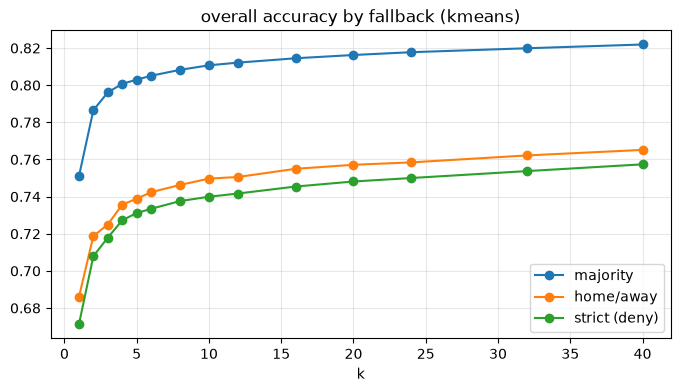

,majority,home/away,strict (deny)
k,,,
1,0.751,0.686,0.671
2,0.787,0.719,0.708
3,0.796,0.725,0.718
4,0.801,0.736,0.727
5,0.803,0.739,0.731
6,0.805,0.742,0.733
8,0.808,0.746,0.738
10,0.811,0.750,0.740
12,0.812,0.751,0.742


In [8]:
fallbacks = cv.loc[PROFILE_METHOD, ["acc_majority", "acc_home_away_80", "acc_strict_80"]].rename(
    columns={"acc_majority": "majority", "acc_home_away_80": "home/away", "acc_strict_80": "strict (deny)"})
ax = fallbacks.plot(marker="o", figsize=(8, 4), title=f"overall accuracy by fallback ({PROFILE_METHOD})"); ax.set_xlabel("k"); ax.grid(alpha=0.3)
plt.show()
fallbacks.round(3)

### Checks

In [9]:
w = cv.loc[PROFILE_METHOD]
checks = {
    f"profiles beat one preset for everyone (k={TEAM_K} vs k=1)": w.loc[TEAM_K, "acc_majority"] > w.loc[1, "acc_majority"] + 0.03,
    "covered decisions are accurate (>= 90% at 80% agreement)": (w.acc_covered_80 >= 0.9).all(),
    "coverage grows with k": w.coverage_80.loc[40] > w.coverage_80.loc[1],
    "real-device items are predicted better than the whole grid": (w.acc_majority_real > w.acc_majority).all(),
    "average linkage builds a dominant profile (as S20 observed)": cv.loc["average_manhattan"].loc[8, "largest_profile"] > 0.4,
}
assert all(checks.values()), checks
pd.Series(checks, name="holds")

profiles beat one preset for everyone (k=4 vs k=1)             True
covered decisions are accurate (>= 90% at 80% agreement)       True
coverage grows with k                                          True
real-device items are predicted better than the whole grid     True
average linkage builds a dominant profile (as S20 observed)    True
Name: holds, dtype: bool

### What this means

- Profiles beat one preset for everyone, with **diminishing returns**: exact accuracy rises from 75% (k = 1) to 81% at
  k = 10 (the team's k) and 82% at k = 40, most of the gain by about k = 6–12 (table above). Choosing k is left to notebook 05, because more profiles
  also need more onboarding questions (S20: pick k by a budget of questions vs accuracy).
- Where a profile reaches 80% agreement (about 59% of items at k = 10) its decision is right about 93% of the time. The rest is each household's own
  item-by-item variation and noise, which no profile can capture (notebook 02 calibrates that noise to Liu et al. 2016).
- Because we may not ask, the **fallback matters**: using the profile's majority keeps accuracy highest; the cautious
  *home/away* rule and *deny* contradict many households' own choices. Which fallback presets should use is a
  product/privacy decision for notebook 04 (accuracy vs caution), not only a statistic.
- The 52 real-device items are predicted better than the grid overall: they are common, less ambiguous flows.

## Profiles on all households

k-means clustering (`PROFILE_METHOD`) of all 5,000 households, cut at the candidate k values. Notebook 04 turns these into presets and
notebook 05 chooses among them; small k values are included so a short list of presets can win if it is enough.

In [10]:
CANDIDATES = [2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24]
assert TEAM_K in CANDIDATES, "decisions.json names a k that is not clustered"
labels_all = cluster(PROFILE_METHOD, C, CANDIDATES, n_init=KMEANS_INIT)
out = DATA / "profiles"; out.mkdir(exist_ok=True)
pd.DataFrame({"household_id": H.household_id, **{f"k{k}": labels_all[k] for k in CANDIDATES}}).to_csv(out / "labels.csv", index=False)
for k in CANDIDATES:
    majority, agreement = build_profiles(D, labels_all[k], k)
    np.savez_compressed(out / f"profiles_k{k}.npz", majority=majority, agreement=agreement.astype(np.float16),
                        size=np.bincount(labels_all[k], minlength=k), centroid=centroids(C, labels_all[k], k).astype(np.float32))
for old in out.glob("*ward*"):   # profile files from the Ward version
    old.unlink()
print("saved", sorted(p.name for p in out.iterdir()))

saved ['labels.csv', 'profiles_k10.npz', 'profiles_k12.npz', 'profiles_k16.npz', 'profiles_k2.npz', 'profiles_k20.npz', 'profiles_k24.npz', 'profiles_k3.npz', 'profiles_k4.npz', 'profiles_k5.npz', 'profiles_k6.npz', 'profiles_k8.npz', 'quality.csv', 'stability_per_profile.csv']


### Are the profiles well defined?

A preset is only worth offering if its profile is a real group, not an accident of one clustering, and if it differs
from every other profile. Two measures per k, saved for notebook 05 (which only chooses a k whose profiles pass):

- **Stability** (Hennig 2007, *Cluster-wise assessment of cluster stability*): recluster `BOOTSTRAPS` bootstrap
  samples of the households; a profile's stability is its average best Jaccard overlap with the bootstrap clusters.
  Hennig's reading: ≥ 0.75 a stable cluster, 0.6–0.75 a pattern but uncertain where its border is, < 0.6 dissolved.
- **Distinctness**: for every pair of profiles, the share of items where their majority decisions differ. Two profiles
  that differ on less than `MIN_DIFFERENT` of items would give households nearly the same preset.

Measured for the profile method (k-means). Ward, measured the same way on the earlier households, was not stable at any
k ≥ 3 (its tree cuts move when a few households change), which is why the profiles use k-means. The table shows up to
which k the profiles stay stable and distinct; beyond it they dissolve.

In [11]:
BOOTSTRAPS, STABLE, MIN_DIFFERENT = 20, 0.75, 0.10
rng = np.random.default_rng(SEED)
stability = {k: np.zeros(k) for k in CANDIDATES}
for b in range(BOOTSTRAPS):
    sample = rng.choice(n, n, replace=True)
    boots = cluster(PROFILE_METHOD, C[sample], CANDIDATES)
    for k in CANDIDATES:
        boot = boots[k]
        orig = labels_all[k][sample]
        for c in range(k):                                    # best Jaccard of each original profile with a bootstrap cluster
            mine = set(np.unique(sample[orig == c]))
            best = max((len(mine & (other := set(np.unique(sample[boot == j])))) / max(len(mine | other), 1)) for j in range(k))
            stability[k][c] += best / BOOTSTRAPS

quality = []
for k in CANDIDATES:
    majority, _ = build_profiles(D, labels_all[k], k)
    differ = np.array([[(majority[a] != majority[b]).mean() for b in range(k)] for a in range(k)])
    off = differ[~np.eye(k, dtype=bool)]
    quality.append({"k": k, "stability (lowest)": stability[k].min(), "stability (mean)": stability[k].mean(),
                    "stable profiles": int((stability[k] >= STABLE).sum()), "dissolved profiles (< 0.6)": int((stability[k] < 0.6).sum()),
                    "most similar pair differs on": off.min(), "well defined": bool((stability[k] >= STABLE).all() and off.min() >= MIN_DIFFERENT)})
quality = pd.DataFrame(quality).set_index("k")
quality.to_csv(out / "quality.csv")
pd.DataFrame({k: pd.Series(np.round(s, 2)) for k, s in stability.items()}).T.fillna("").to_csv(out / "stability_per_profile.csv")
quality.round(3)

/tmp/ipykernel_2254577/1293133392.py:25: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame({k: pd.Series(np.round(s, 2)) for k, s in stability.items()}).T.fillna("").to_csv(out / "stability_per_profile.csv")


,stability (lowest),stability (mean),stable profiles,dissolved profiles (< 0.6),most similar pair differs on,well defined
k,,,,,,
2,0.990,0.991,2,0,0.319,True
3,0.967,0.972,3,0,0.217,True
4,0.944,0.953,4,0,0.172,True
5,0.600,0.746,3,0,0.137,False
6,0.618,0.755,3,0,0.133,False
8,0.471,0.638,2,4,0.114,False
10,0.371,0.540,1,8,0.086,False
12,0.289,0.488,2,10,0.097,False
16,0.204,0.420,1,14,0.080,False


### Compared with the studies

None of these was a target in notebook 02, so they test the synthetic households independently:

| Measure | Study | What real data showed |
| --- | --- | --- |
| Allow/deny accuracy of profiles across k | S20 §4.3 | 75–90%; a few points more with purpose |
| Cluster overlap (silhouette) | S20 §4.3.2 | 0.03 and −0.07 at k = 20: profiles overlap heavily |
| Cluster sizes at k = 6 | Liu 2019 §6 | Six clusters of 156 Play Store users: 17, 39, 25, 21, 17, 37 |

In [12]:
targets = pd.read_csv(REF / "extracted" / "targets.csv").set_index("target")
low, high = float(targets.loc["profile_accuracy", "low"]), float(targets.loc["profile_accuracy", "high"])
liu = np.sort(np.array(targets.loc["deployment_cluster_sizes", "value"].split("|"), dtype=float))[::-1]
liu_share = liu / liu.sum()

compare_labels = cluster(PROFILE_METHOD, C, [6, 20], n_init=KMEANS_INIT)
sample = np.random.default_rng(SEED).choice(n, 2000, replace=False)   # silhouette on a sample keeps it fast
silhouette = {k: silhouette_score(C[sample], (compare_labels[k] if k in compare_labels else labels_all[k])[sample])
              for k in sorted({6, 20, *CANDIDATES})}
ours_share = np.sort(np.bincount(compare_labels[6]) / n)[::-1]
sizes = pd.DataFrame({"Liu 2019 (156 users)": liu_share, f"{PROFILE_METHOD} k = 6 (synthetic)": ours_share}, index=range(1, 7)).round(3)

allow_deny = cv.loc[PROFILE_METHOD].acc_allow_deny
compare = {
    "allow/deny accuracy within S20's 75-90% for every k >= 2": allow_deny.drop(1).between(low, high).all(),
    "profiles overlap like S20's (silhouette at k = 20 below 0.1)": silhouette[20] < 0.1,
    "cluster sizes at k = 6 within 6 points of Liu's": np.abs(ours_share - liu_share).max() <= 0.06,
}
print(f"allow/deny accuracy ({PROFILE_METHOD}):", allow_deny.round(3).to_dict())
print(f"silhouette ({PROFILE_METHOD}, 2,000 households):", {k: round(v, 3) for k, v in silhouette.items()})
display(sizes)
assert all(compare.values()), compare
pd.Series(compare, name="holds")

allow/deny accuracy (kmeans): {1: 0.772, 2: 0.811, 3: 0.819, 4: 0.824, 5: 0.827, 6: 0.829, 8: 0.832, 10: 0.835, 12: 0.836, 16: 0.839, 20: 0.841, 24: 0.843, 32: 0.845, 40: 0.847}
silhouette (kmeans, 2,000 households): {2: 0.172, 3: 0.102, 4: 0.068, 5: 0.064, 6: 0.052, 8: 0.049, 10: 0.045, 12: 0.044, 16: 0.041, 20: 0.037, 24: 0.035}


,Liu 2019 (156 users),kmeans k = 6 (synthetic)
1,0.250,0.243
2,0.237,0.179
3,0.160,0.175
4,0.135,0.156
5,0.109,0.136
6,0.109,0.112


allow/deny accuracy within S20's 75-90% for every k >= 2        True
profiles overlap like S20's (silhouette at k = 20 below 0.1)    True
cluster sizes at k = 6 within 6 points of Liu's                 True
Name: holds, dtype: bool

The synthetic profiles land inside S20's accuracy range, overlap as much as S20's real profiles did, and at k = 6 split
households in nearly the same proportions as Liu's deployed assistant. That is support for the household model's
structure, not proof: each comparison crosses a domain (mobile apps → home devices).

### What the profiles look like (the team's k, from `decisions.json`)

Average acceptance (deny 0, allow-if 0.5, allow 1) of each profile per purpose, per handling context and per data type,
shown as the difference from all households. Red = stricter than average, blue = more accepting.

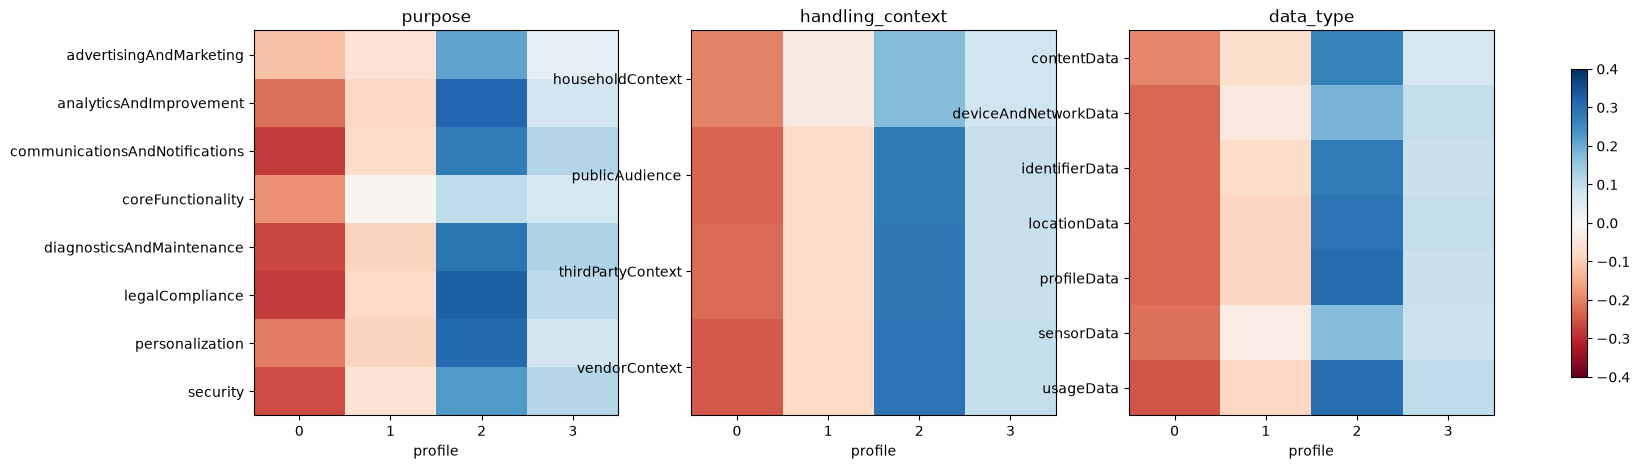

,households,acceptance,concern (avg),content data (effect),maker context (effect),owns a camera,trust in maker (avg),ads (effect),analytics (effect)
0,960,0.28,0.56,-0.35,-1.79,0.31,0.36,-3.20,-2.01
1,1735,0.44,0.52,-0.31,-1.55,0.34,0.46,-3.00,-1.79
2,754,0.76,0.45,-0.22,-1.00,0.36,0.69,-2.29,-1.19
3,1551,0.59,0.48,-0.30,-1.34,0.35,0.54,-2.70,-1.57


In [13]:
K = TEAM_K
lab = labels_all[K]
ordinal = np.array([0.0, 1.0, 0.5, 0.5, 0.5], dtype=np.float32)
V = ordinal[D]
overall = V.mean(axis=0)
def by(field):
    groups = items[field].map(short)
    prof = pd.DataFrame({c: pd.Series(V[lab == c].mean(axis=0)).groupby(groups).mean() for c in range(K)})
    return prof.sub(pd.Series(overall).groupby(groups).mean(), axis=0)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, field in zip(axes, ["purpose", "handling_context", "data_type"]):
    t = by(field)
    im = ax.imshow(t.values, cmap="RdBu", vmin=-0.4, vmax=0.4, aspect="auto")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.set_xticks(range(K)); ax.set_xlabel("profile"); ax.set_title(field)
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()
summary = pd.DataFrame({
    "households": np.bincount(lab, minlength=K),
    "acceptance": [V[lab == c].mean() for c in range(K)],
    "concern (avg)": [H.concern[lab == c].mean() for c in range(K)],
    "content data (effect)": [H.dtype_contentData[lab == c].mean() for c in range(K)],
    "maker context (effect)": [H.ctx_vendorContext[lab == c].mean() for c in range(K)],
    "owns a camera": [H.owns_camera[lab == c].mean() for c in range(K)],
    "trust in maker (avg)": [H.vendor_trust[lab == c].mean() for c in range(K)],
    "ads (effect)": [H.att_advertisingAndMarketing[lab == c].mean() for c in range(K)],
    "analytics (effect)": [H.att_analyticsAndImprovement[lab == c].mean() for c in range(K)],
})
summary.round(2)

Profiles differ in **which** purposes, handling contexts and data types they accept, not only in overall strictness.
The household columns (notebook 02's effects on the log-odds of allowing, and device classes owned) show what sets each
profile apart. Naming them ("keeps video home", "fine with analytics, no ads", …) is part of notebook 04.